In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [2]:
OUTPUT_DIR = Path("../visualizations")

if not OUTPUT_DIR.exists():
    OUTPUT_DIR.mkdir(parents=True)
    
print("Visualization folder is ready.")

Visualization folder is ready.


In [4]:
#  CELL 3 — Dataset Automatically Find

possible_locations = [
    Path("../data"),
    Path("data"),
    Path("."),
]

data_file = None

for location in possible_locations:
    if location.exists():
        matching_files = list(location.glob("*.xls")) + list(location.glob("*.xlsx"))
        
        if matching_files:
            data_file = matching_files[0]
            break

if data_file is None:
    raise FileNotFoundError(
        "Superstore Excel file नहीं मिली। "
        "कृपया file को project के 'data' folder में रखें।"
    )

print("Dataset found at:")
print(data_file)

Dataset found at:
..\data\sample_-_superstore(1).xls


In [5]:
#  CELL 4 — Dataset Load

if data_file.suffix.lower() == ".xls":
    df = pd.read_excel(data_file, engine="xlrd")
else:
    df = pd.read_excel(data_file, engine="openpyxl")

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 10194
Columns: 21


In [6]:
#  CELL 5 — First Look

display(df.head())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,US-2023-103800,2023-01-03,2023-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,2,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
2,3,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
3,4,US-2023-112326,2023-01-04,2023-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
4,5,US-2023-141817,2023-01-05,2023-01-12,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [7]:
display(df.tail())

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country/Region,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
10189,10190,US-2026-143259,2026-12-30,2027-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,OFF-BI-10003684,Office Supplies,Binders,Wilson Jones Legal Size Ring Binders,52.776,3,0.2,19.7910
10190,10191,US-2026-115427,2026-12-30,2027-01-03,Standard Class,EB-13975,Erica Bern,Corporate,United States,Fairfield,...,94533,West,OFF-BI-10004632,Office Supplies,Binders,GBC Binding covers,20.720,2,0.2,6.4750
10191,10192,US-2026-156720,2026-12-30,2027-01-03,Standard Class,JM-15580,Jill Matthias,Consumer,United States,Loveland,...,80538,West,OFF-FA-10003472,Office Supplies,Fasteners,Bagged Rubber Bands,3.024,3,0.2,-0.6048
10192,10193,US-2026-143259,2026-12-30,2027-01-03,Standard Class,PO-18865,Patrick O'Donnell,Consumer,United States,New York City,...,10009,East,TEC-PH-10004774,Technology,Phones,Gear Head AU3700S Headset,90.930,7,0.0,2.7279
10193,10194,CA-2026-143500,2026-12-30,2027-01-03,Standard Class,HO-15230,Harry Olson,Consumer,Canada,Charlottetown,...,C0A,East,OFF-BI-10004040,Office Supplies,Binders,Wilson Jones Impact Binders,3.024,3,0.2,-0.6048


In [8]:
#  CELL 6 — Column Names

print("Dataset Columns:")
for column in df.columns:
    print("-", column)

Dataset Columns:
- Row ID
- Order ID
- Order Date
- Ship Date
- Ship Mode
- Customer ID
- Customer Name
- Segment
- Country/Region
- City
- State/Province
- Postal Code
- Region
- Product ID
- Category
- Sub-Category
- Product Name
- Sales
- Quantity
- Discount
- Profit


In [9]:
# CELL 7 — Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  str           
 2   Order Date      10194 non-null  datetime64[us]
 3   Ship Date       10194 non-null  datetime64[us]
 4   Ship Mode       10194 non-null  str           
 5   Customer ID     10194 non-null  str           
 6   Customer Name   10194 non-null  str           
 7   Segment         10194 non-null  str           
 8   Country/Region  10194 non-null  str           
 9   City            10194 non-null  str           
 10  State/Province  10194 non-null  str           
 11  Postal Code     10194 non-null  object        
 12  Region          10194 non-null  str           
 13  Product ID      10194 non-null  str           
 14  Category        10194 non-null  str           
 15  Sub-Category 

In [10]:
#  CELL 8 — Dataset Shape

rows, columns = df.shape

print(f"Number of rows: {rows}")
print(f"Number of columns: {columns}")

Number of rows: 10194
Number of columns: 21


In [11]:
#  CELL 9 — Duplicate Check

duplicate_count = df.duplicated().sum()

print(f"Duplicate rows: {duplicate_count}")

Duplicate rows: 0


In [12]:
#  CELL 10 — Missing Values

missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0]

if missing_values.empty:
    print("No missing values found.")
else:
    print("Columns containing missing values:")
    print(missing_values)

No missing values found.


In [13]:
#  CELL 11 — Data Types Correct

df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    errors="coerce"
)

numeric_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

print(df[numeric_columns].dtypes)

Sales       float64
Quantity      int64
Discount    float64
Profit      float64
dtype: object


In [14]:
#  CELL 12 — Data Validation

required_columns = [
    "Order Date",
    "Ship Date",
    "Ship Mode",
    "Segment",
    "Region",
    "Category",
    "Sub-Category",
    "Sales",
    "Quantity",
    "Discount",
    "Profit"
]

missing_required_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_required_columns:
    raise ValueError(
        f"Required columns missing: {missing_required_columns}"
    )

print("All required columns are available.")

All required columns are available.


In [15]:
#  CELL 13 — Remove Invalid Required Records

before_cleaning = len(df)

df = df.dropna(
    subset=[
        "Order Date",
        "Ship Date",
        "Sales",
        "Quantity",
        "Discount",
        "Profit"
    ]
)

after_cleaning = len(df)

print("Rows before cleaning:", before_cleaning)
print("Rows after cleaning:", after_cleaning)
print("Rows removed:", before_cleaning - after_cleaning)

Rows before cleaning: 10194
Rows after cleaning: 10194
Rows removed: 0


In [16]:
#  CELL 14 — Validate Numeric Values

print("Negative Sales:", (df["Sales"] < 0).sum())
print("Invalid Quantity:", (df["Quantity"] <= 0).sum())
print("Invalid Discount:", ((df["Discount"] < 0) | (df["Discount"] > 1)).sum())

Negative Sales: 0
Invalid Quantity: 0
Invalid Discount: 0


In [17]:
#  CELL 15 — Shipping Days

df["Shipping Days"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print(df["Shipping Days"].describe())

count    10194.000000
mean         3.961350
std          1.742829
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         11.000000
Name: Shipping Days, dtype: float64


In [18]:
# CELL 16 — Date Features

df["Year"] = df["Order Date"].dt.year

df["Month"] = df["Order Date"].dt.month

df["Month Name"] = df["Order Date"].dt.strftime("%b")

df["Year-Month"] = (
    df["Order Date"]
    .dt.to_period("M")
    .astype(str)
)

print(
    df[
        [
            "Order Date",
            "Year",
            "Month",
            "Month Name",
            "Year-Month"
        ]
    ].head()
)

  Order Date  Year  Month Month Name Year-Month
0 2023-01-03  2023      1        Jan    2023-01
1 2023-01-04  2023      1        Jan    2023-01
2 2023-01-04  2023      1        Jan    2023-01
3 2023-01-04  2023      1        Jan    2023-01
4 2023-01-05  2023      1        Jan    2023-01


In [19]:
#  CELL 17 — Profit Margin

df["Profit Margin (%)"] = np.where(
    df["Sales"] != 0,
    (df["Profit"] / df["Sales"]) * 100,
    np.nan
)

print(df["Profit Margin (%)"].describe())

count    10194.000000
mean        12.221784
std         46.488992
min       -275.000000
25%          7.500000
50%         27.000000
75%         36.250000
max         50.000000
Name: Profit Margin (%), dtype: float64


In [ ]:
#  Basic Statistical Analysis
#  CELL 18 — Descriptive Statistics

descriptive_statistics = df[
    [
        "Sales",
        "Quantity",
        "Discount",
        "Profit",
        "Shipping Days"
    ]
].describe()

display(descriptive_statistics.round(2))

,Sales,Quantity,Discount,Profit,Shipping Days
count,10194.00,10194.00,10194.00,10194.00,10194.00
mean,228.23,3.79,0.16,28.67,3.96
std,619.91,2.23,0.21,232.47,1.74
min,0.44,1.00,0.00,-6599.98,0.00
25%,17.22,2.00,0.00,1.76,3.00
50%,53.91,3.00,0.20,8.69,4.00
75%,209.50,5.00,0.20,29.30,5.00
max,22638.48,14.00,0.80,8399.98,11.00


In [21]:
# CELL 19 — Important KPIs

total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_quantity = df["Quantity"].sum()
total_orders = df["Order ID"].nunique()

average_order_value = (
    total_sales / total_orders
)

overall_profit_margin = (
    total_profit / total_sales
) * 100

average_shipping_days = df["Shipping Days"].mean()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Total Quantity: {total_quantity:,}")
print(f"Total Orders: {total_orders:,}")
print(f"Average Order Value: ${average_order_value:,.2f}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")
print(f"Average Shipping Days: {average_shipping_days:.2f}")

Total Sales: $2,326,534.35
Total Profit: $292,296.81
Total Quantity: 38,654
Total Orders: 5,111
Average Order Value: $455.20
Overall Profit Margin: 12.56%
Average Shipping Days: 3.96


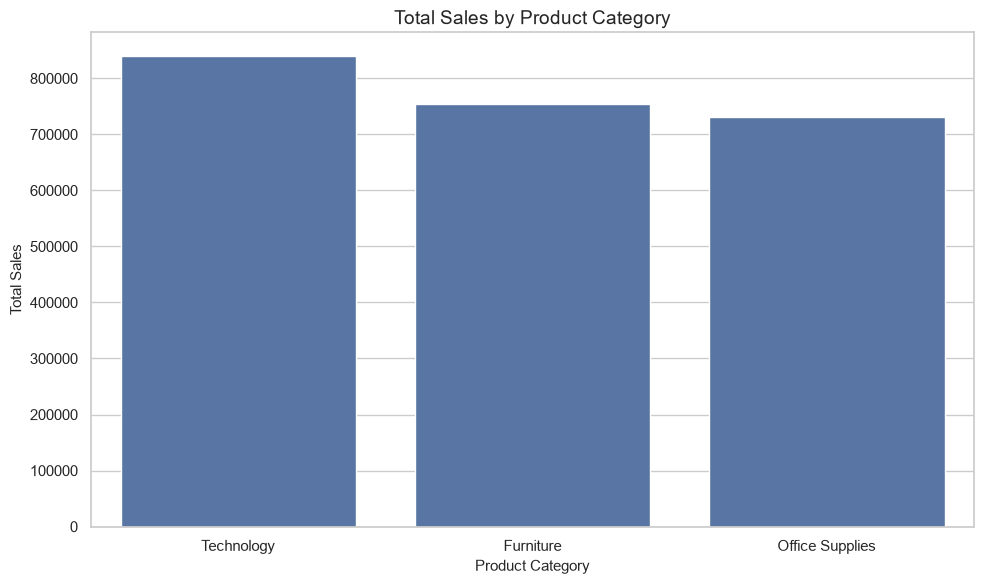

In [22]:
# Visualization 1
# Sales by Category

category_sales = (
    df.groupby("Category")["Sales"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values
)

plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sales_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

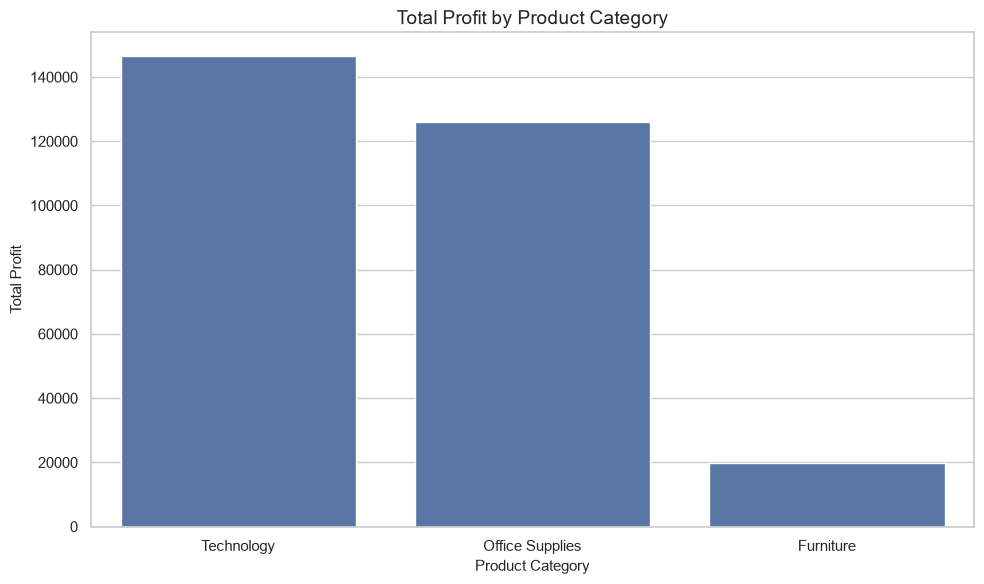

In [23]:
# Visualization 2 — Profit by Category

category_profit = (
    df.groupby("Category")["Profit"]
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_profit.index,
    y=category_profit.values
)

plt.title("Total Profit by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Profit")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "profit_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

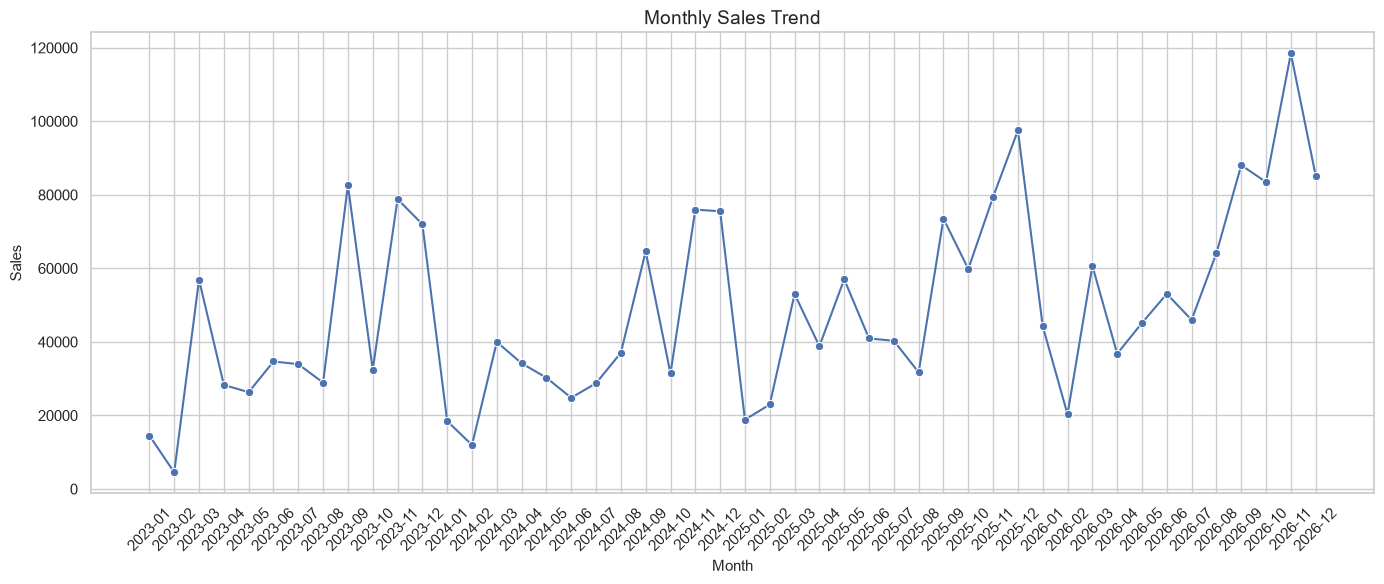

In [24]:
# Visualization 3 — Monthly Sales Trend

monthly_sales = (
    df.groupby("Year-Month")["Sales"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_sales,
    x="Year-Month",
    y="Sales",
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_sales_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


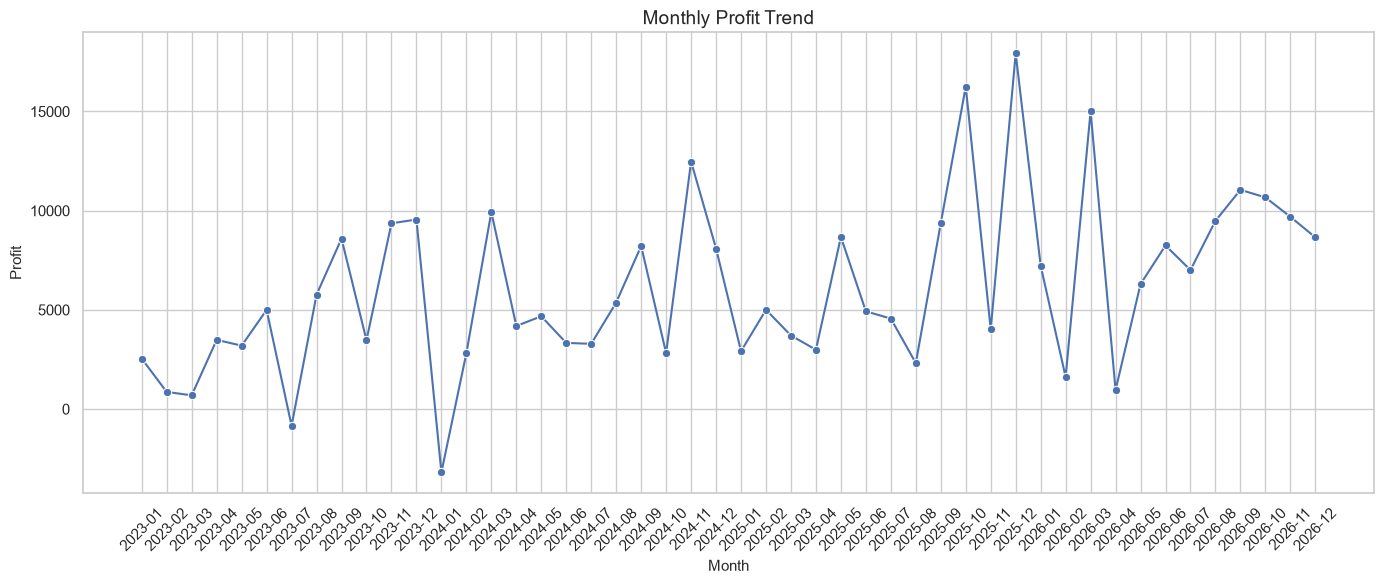

In [25]:
#  Visualization 4 — Monthly Profit Trend

monthly_profit = (
    df.groupby("Year-Month")["Profit"]
    .sum()
    .reset_index()
)

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=monthly_profit,
    x="Year-Month",
    y="Profit",
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "monthly_profit_trend.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [26]:
#  Visualization 5 — Regional Performance

region_sales_profit = (
    df.groupby("Region")[["Sales", "Profit"]]
    .sum()
    .sort_values("Sales", ascending=False)
)

display(region_sales_profit.round(2))

,Sales,Profit
Region,,
West,739813.61,110798.82
East,691828.17,94883.26
Central,503170.67,39865.31
South,391721.90,46749.43


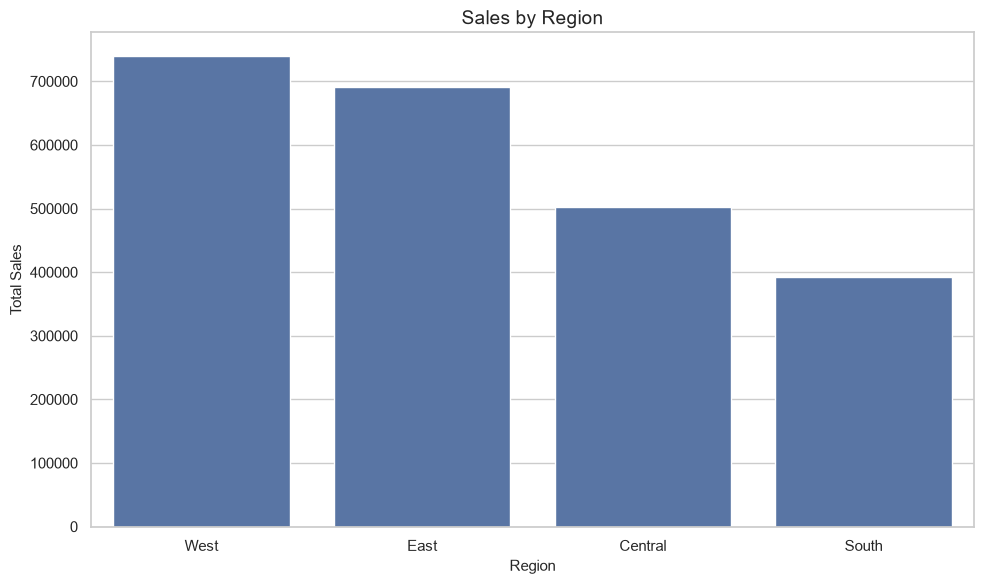

In [27]:
#plt.figure(figsize=(10, 6))

sns.barplot(
    data=region_sales_profit.reset_index(),
    x="Region",
    y="Sales"
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sales_by_region.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

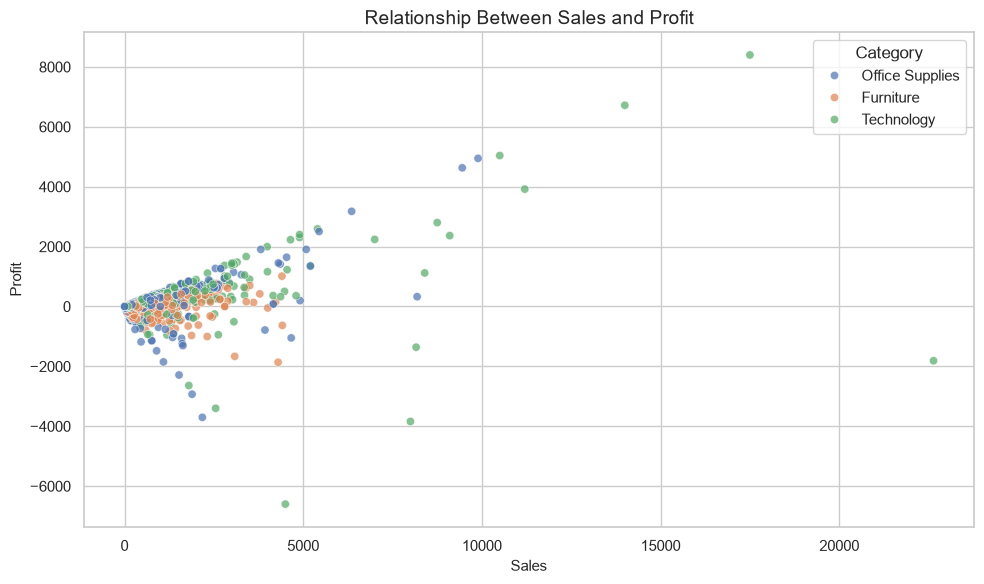

In [28]:
#  Visualization 6 — Sales vs Profit

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Sales",
    y="Profit",
    hue="Category",
    alpha=0.7
)

plt.title("Relationship Between Sales and Profit")
plt.xlabel("Sales")
plt.ylabel("Profit")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "sales_vs_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

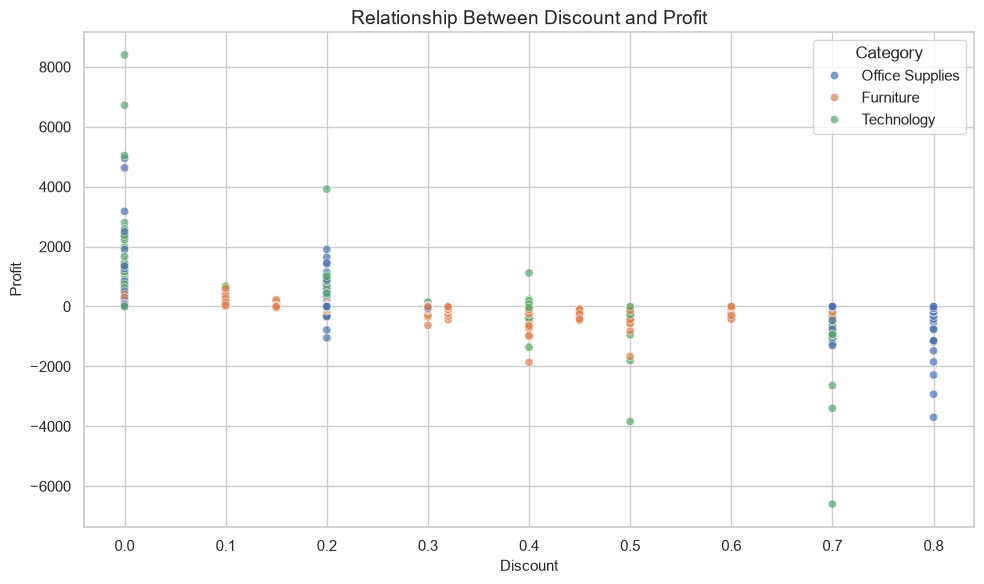

In [29]:
#  Visualization 7 — Discount vs Profit

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Discount",
    y="Profit",
    hue="Category",
    alpha=0.7
)

plt.title("Relationship Between Discount and Profit")
plt.xlabel("Discount")
plt.ylabel("Profit")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "discount_vs_profit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

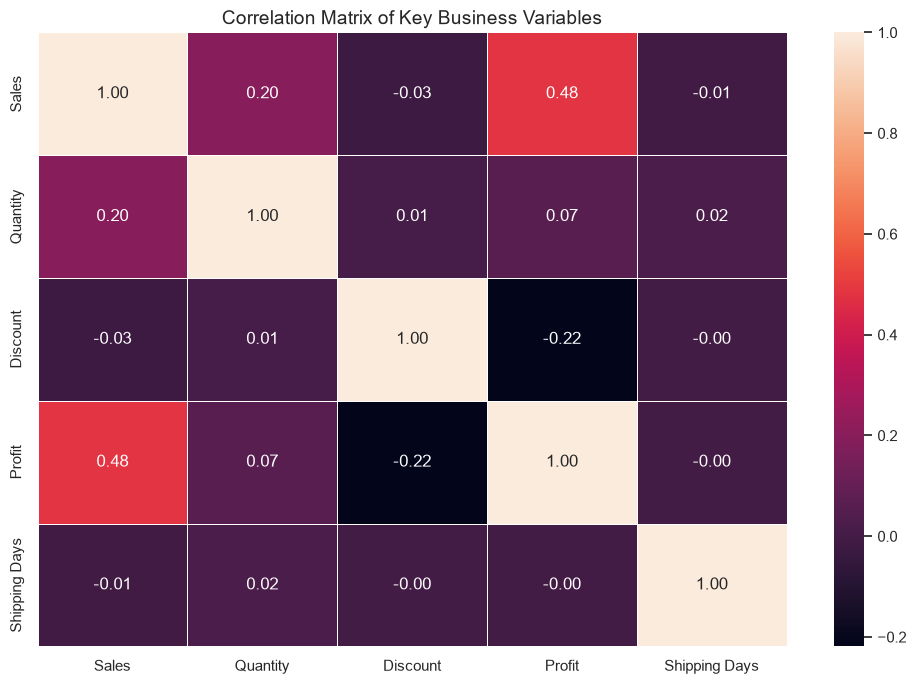

In [30]:
#  Visualization 8 — Correlation Heatmap

correlation_columns = [
    "Sales",
    "Quantity",
    "Discount",
    "Profit",
    "Shipping Days"
]

correlation_matrix = df[
    correlation_columns
].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Key Business Variables")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

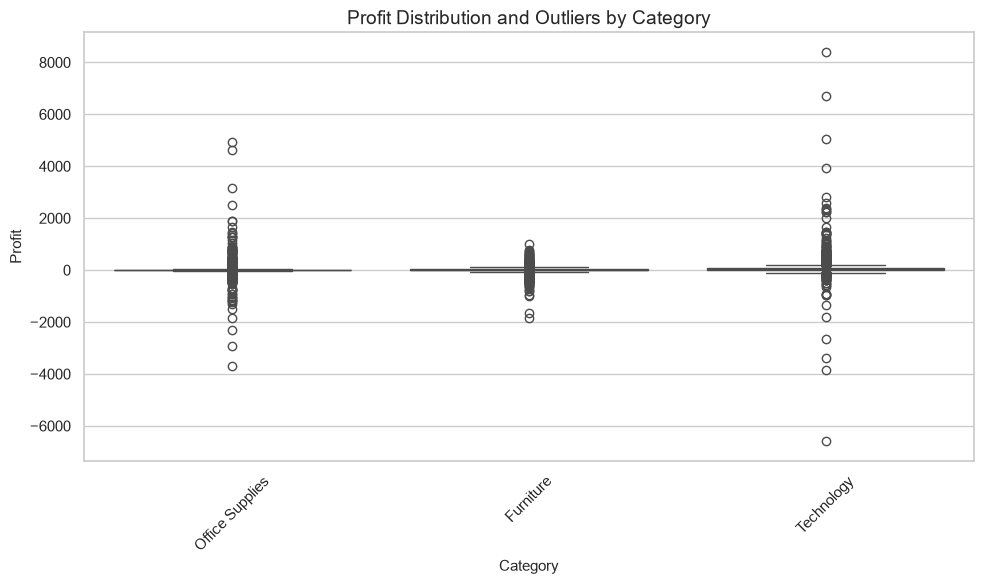

In [31]:
#  Visualization 9 — Profit Distribution / Outliers


plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Category",
    y="Profit"
)

plt.title("Profit Distribution and Outliers by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "profit_outliers_by_category.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

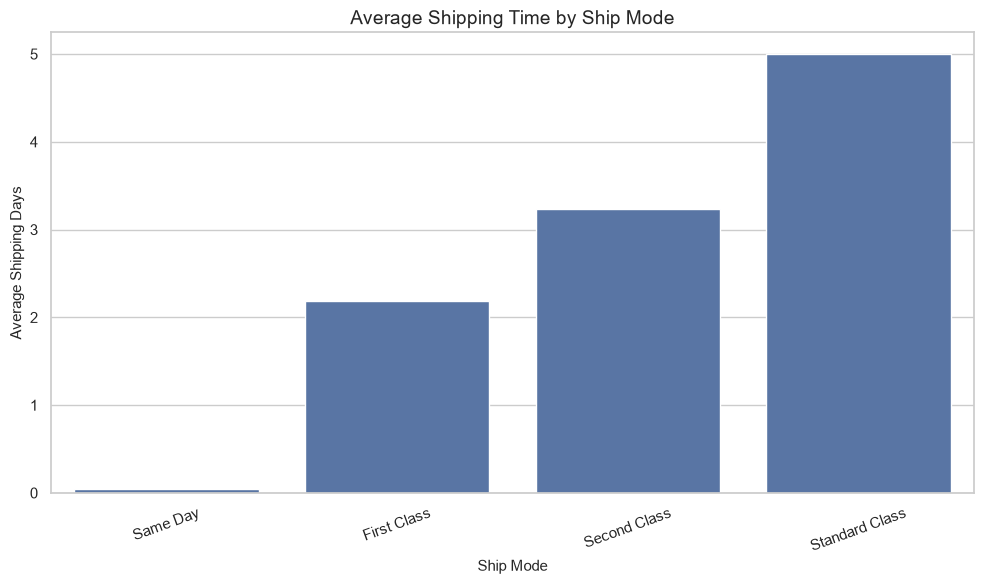

In [32]:
#  Visualization 10 — Shipping Performance

shipping_summary = (
    df.groupby("Ship Mode")["Shipping Days"]
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=shipping_summary.index,
    y=shipping_summary.values
)

plt.title("Average Shipping Time by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Shipping Days")
plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "shipping_days_by_mode.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [33]:
# Statistical Analysis

# CELL 20 — Pearson & Spearman Correlation

numeric_data = df[
    [
        "Sales",
        "Quantity",
        "Discount",
        "Profit",
        "Shipping Days"
    ]
]

pearson_correlation = numeric_data.corr(method="pearson")
spearman_correlation = numeric_data.corr(method="spearman")

print("Pearson Correlation:")
display(pearson_correlation.round(3))

print("\nSpearman Correlation:")
display(spearman_correlation.round(3))

Pearson Correlation:


,Sales,Quantity,Discount,Profit,Shipping Days
Sales,1.000,0.198,-0.028,0.481,-0.007
Quantity,0.198,1.000,0.007,0.066,0.021
Discount,-0.028,0.007,1.000,-0.219,-0.002
Profit,0.481,0.066,-0.219,1.000,-0.004
Shipping Days,-0.007,0.021,-0.002,-0.004,1.000



Spearman Correlation:


,Sales,Quantity,Discount,Profit,Shipping Days
Sales,1.000,0.326,-0.053,0.520,-0.015
Quantity,0.326,1.000,-0.001,0.235,0.019
Discount,-0.053,-0.001,1.000,-0.541,-0.016
Profit,0.520,0.235,-0.541,1.000,-0.006
Shipping Days,-0.015,0.019,-0.016,-0.006,1.000


In [34]:
# CELL 21 — Specific Discount vs Profit Test

discount_profit_corr, discount_profit_p = stats.pearsonr(
    df["Discount"],
    df["Profit"]
)

print(f"Pearson correlation: {discount_profit_corr:.4f}")
print(f"P-value: {discount_profit_p:.6f}")

Pearson correlation: -0.2189
P-value: 0.000000


In [35]:
# # Regression Analysis

# CELL 22 — Regression Model

regression_model = smf.ols(
    "Profit ~ Sales + Quantity + Discount",
    data=df
).fit(
    cov_type="HC3"
)

print(regression_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.275
Model:                            OLS   Adj. R-squared:                  0.275
Method:                 Least Squares   F-statistic:                     107.6
Date:                Thu, 01 Oct 2026   Prob (F-statistic):           1.35e-68
Time:                        22:31:09   Log-Likelihood:                -68371.
No. Observations:               10194   AIC:                         1.367e+05
Df Residuals:                   10190   BIC:                         1.368e+05
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     34.4513      5.412      6.366      0.0

In [36]:
#  CELL 23 — Regression Results Table

regression_results = pd.DataFrame({
    "Coefficient": regression_model.params,
    "P-Value": regression_model.pvalues,
    "Lower CI": regression_model.conf_int()[0],
    "Upper CI": regression_model.conf_int()[1]
})

display(regression_results.round(4))

,Coefficient,P-Value,Lower CI,Upper CI
Intercept,34.4513,0.0000,23.8444,45.0581
Sales,0.1805,0.0011,0.0722,0.2888
Quantity,-2.9037,0.2914,-8.2979,2.4904
Discount,-231.4131,0.0000,-271.0830,-191.7433


In [37]:
#  CELL 24 — Regression Interpretation

print(f"R-squared: {regression_model.rsquared:.4f}")
print(f"Adjusted R-squared: {regression_model.rsquared_adj:.4f}")

R-squared: 0.2748
Adjusted R-squared: 0.2746


In [38]:
#  Regression with Categories and Regions

extended_model = smf.ols(
    "Profit ~ Sales + Quantity + Discount + C(Category) + C(Region)",
    data=df
).fit(
    cov_type="HC3"
)

print(extended_model.summary())

                            OLS Regression Results                            
Dep. Variable:                 Profit   R-squared:                       0.282
Model:                            OLS   Adj. R-squared:                  0.282
Method:                 Least Squares   F-statistic:                     76.57
Date:                Thu, 01 Oct 2026   Prob (F-statistic):          2.74e-123
Time:                        22:32:52   Log-Likelihood:                -68317.
No. Observations:               10194   AIC:                         1.367e+05
Df Residuals:                   10185   BIC:                         1.367e+05
Df Model:                           8                                         
Covariance Type:                  HC3                                         
                                     coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept   

In [39]:
# #  Hypothesis Testing
# CELL 25 — ANOVA

category_groups = [
    group["Profit"].dropna()
    for _, group in df.groupby("Category")
]

anova_statistic, anova_p_value = stats.f_oneway(
    *category_groups
)

print(f"ANOVA F-statistic: {anova_statistic:.4f}")
print(f"ANOVA p-value: {anova_p_value:.6f}")

ANOVA F-statistic: 55.1895
ANOVA p-value: 0.000000


In [40]:
#  CELL 26 — Variance Assumption Check

levene_statistic, levene_p_value = stats.levene(
    *category_groups,
    center="median"
)

print(f"Levene statistic: {levene_statistic:.4f}")
print(f"Levene p-value: {levene_p_value:.6f}")

Levene statistic: 83.2650
Levene p-value: 0.000000


In [41]:
#  CELL 27 — Non-Parametric Backup Test

kruskal_statistic, kruskal_p_value = stats.kruskal(
    *category_groups
)

print(f"Kruskal-Wallis statistic: {kruskal_statistic:.4f}")
print(f"Kruskal-Wallis p-value: {kruskal_p_value:.6f}")

Kruskal-Wallis statistic: 450.7268
Kruskal-Wallis p-value: 0.000000


In [42]:
#  CELL 28 — Tukey Post-Hoc Test

tukey_result = pairwise_tukeyhsd(
    endog=df["Profit"],
    groups=df["Category"],
    alpha=0.05
)

print(tukey_result)

         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1          group2     meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------
      Furniture Office Supplies  11.6011 0.1077 -1.8685 25.0707  False
      Furniture      Technology  69.6114    0.0 52.5521 86.6707   True
Office Supplies      Technology  58.0104    0.0 43.6758 72.3449   True
----------------------------------------------------------------------


In [44]:
# Category Summary

category_summary = (
    df.groupby("Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Profit=("Profit", "mean"),
        Total_Quantity=("Quantity", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(category_summary.round(2))

,Total_Sales,Total_Profit,Average_Sales,Average_Profit,Total_Quantity,Average_Discount
Category,,,,,,
Technology,839893.28,146543.38,450.34,78.58,7017,0.13
Furniture,754747.76,19730.00,342.91,8.96,8369,0.17
Office Supplies,731893.31,126023.44,119.43,20.57,23268,0.16


In [45]:
#  Region Summary

region_summary = (
    df.groupby("Region")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Sales=("Sales", "mean"),
        Average_Profit=("Profit", "mean"),
        Total_Quantity=("Quantity", "sum"),
        Average_Discount=("Discount", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(region_summary.round(2))

,Total_Sales,Total_Profit,Average_Sales,Average_Profit,Total_Quantity,Average_Discount
Region,,,,,,
West,739813.61,110798.82,227.43,34.06,12466,0.11
East,691828.17,94883.26,231.69,31.78,11159,0.14
Central,503170.67,39865.31,215.49,17.07,8820,0.24
South,391721.90,46749.43,241.80,28.86,6209,0.15


In [46]:
#  Sub-Category Analysis

subcategory_summary = (
    df.groupby("Sub-Category")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Average_Profit=("Profit", "mean")
    )
    .sort_values("Total_Sales", ascending=False)
)

display(subcategory_summary.round(2))

,Total_Sales,Total_Profit,Average_Profit
Sub-Category,,,
Chairs,335768.25,27223.53,42.94
Phones,331842.64,45050.83,49.89
Storage,224644.55,21285.11,24.87
Tables,208020.18,-17753.21,-54.46
Binders,207354.88,31426.10,20.30
Machines,189925.03,3461.98,29.59
Accessories,167380.32,41936.64,54.11
Copiers,150745.29,56093.94,801.34
Bookcases,115361.20,-3632.07,-15.66


In [47]:
#  Top 10 Products

top_products = (
    df.groupby("Product Name")["Sales"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

display(top_products.round(2))

Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.82
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.38
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.48
HON 5400 Series Task Chairs for Big and Tall                                   21870.58
GBC DocuBind TL300 Electric Binding System                                     19823.48
GBC Ibimaster 500 Manual ProClick Binding System                               19024.50
Hewlett Packard LaserJet 3310 Copier                                           18839.69
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.90
GBC DocuBind P400 Electric Binding System                                      17965.07
High Speed Automatic Electric Letter Opener                                    17030.31
Name: Sales, dtype: float64

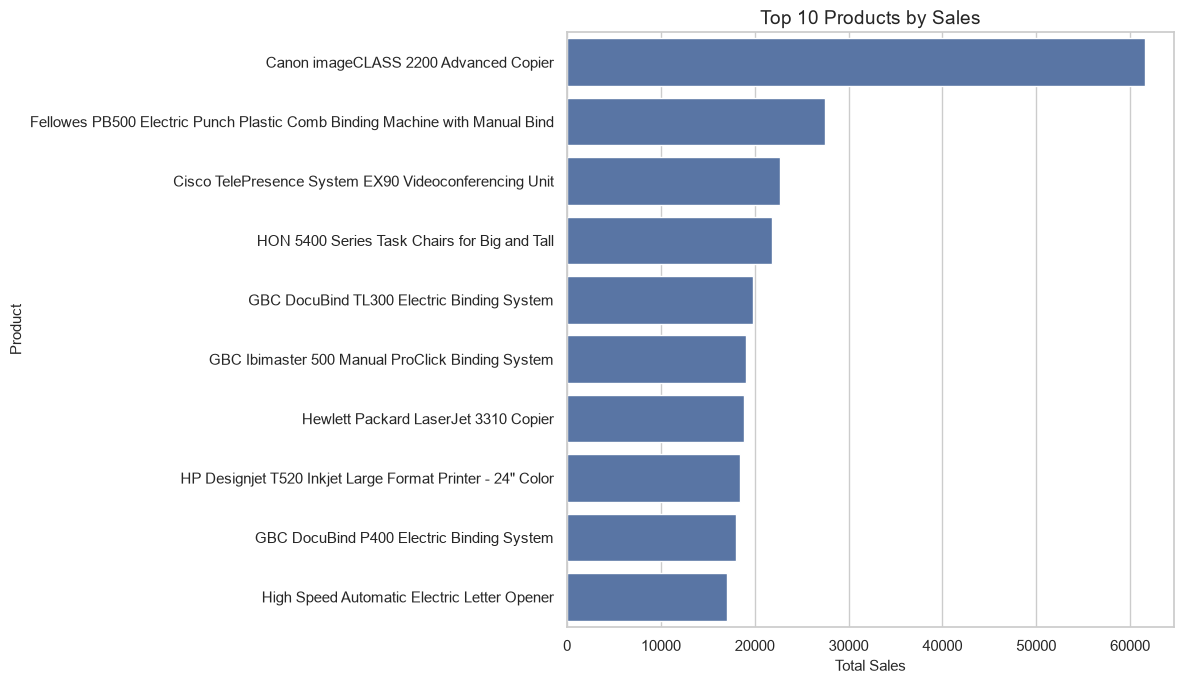

In [ ]:
#  Chart

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_products.values,
    y=top_products.index
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "top_10_products.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [49]:
#  Save Clean Dataset

cleaned_file = Path("../data/superstore_cleaned.csv")

df.to_csv(
    cleaned_file,
    index=False
)

print("Cleaned dataset saved to:")
print(cleaned_file)

Cleaned dataset saved to:
..\data\superstore_cleaned.csv


In [50]:
#  Final Data Quality Check

print("FINAL DATA QUALITY CHECK")
print("-" * 40)

print("Rows:", len(df))
print("Columns:", len(df.columns))
print("Duplicates:", df.duplicated().sum())
print("Missing values:", df.isna().sum().sum())

print("\nDate range:")
print(df["Order Date"].min(), "to", df["Order Date"].max())

print("\nNumeric columns:")
print(df[
    ["Sales", "Quantity", "Discount", "Profit", "Shipping Days"]
].dtypes)

FINAL DATA QUALITY CHECK
----------------------------------------
Rows: 10194
Columns: 27
Duplicates: 0
Missing values: 0

Date range:
2023-01-03 00:00:00 to 2026-12-30 00:00:00

Numeric columns:
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
Shipping Days      int64
dtype: object
